### GLANCE_2_filter_by_shapefile

In [1]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, Polygon
import numpy as np
import matplotlib.pyplot as plt
import time

In [ ]:
print(gpd.__version__)

## Read dataframe. Global with level2 classes

In [2]:
# read geodataframe from file
gdf = gpd.read_parquet('../GLANCE_data/gdf_glance_all_2018_level3.parquet')
len(gdf)

977765

In [ ]:
gdf.head(2)

In [3]:
#level1_new = ['Water(0)','Developed(1)','Barren(2)','Trees(3)','Shrub(4)','Herbaceous(5)']  
#level2_new = ['Water(0)','Developed(1)','Barren(2)','Trees(3)','Shrub(4)','Grassland(5)', 'Agriculture(6)','Undefined(7)'] 
level3 = ['Water(0)','Developed(1)','Barren(2)','Trees(3)','Shrub(4)','Grassland(5)','Agriculture(6)']  

In [6]:
# How many samples per landcover class

sum=0
for i in range(0,7):
    y=np.sum((gdf['level3'] == i))
    print(i, level3[i], '=', y)
    sum=sum+y
print('Total Samples =',sum,'\n')

0 Water(0) = 141927
1 Developed(1) = 11311
2 Barren(2) = 18650
3 Trees(3) = 558514
4 Shrub(4) = 25847
5 Grassland(5) = 166561
6 Agriculture(6) = 54955
Total Samples = 977765 



## Read biome shapefile and plot

In [8]:
# Path to shapefile
shapefile_path = '../WWF_TEOW/Biome_Shapefiles/'

gdf_biomeA_shp = gpd.read_file(shapefile_path + 'Biome_2.shp')    # A - Tropical and Subtropical Dry Broadleaf Forests 
gdf_biomeB_shp = gpd.read_file(shapefile_path + 'Biome_7.shp')    # B - Tropical and Subtropical Grasslands, Savannas, and Shrublands 
gdf_biomeC_shp = gpd.read_file(shapefile_path + 'Biome_8.shp')    # C - Temparate Grasslands, Savannas, and Shrublands 
gdf_biomeD_shp = gpd.read_file(shapefile_path + 'Biome_10.shp')   # D - Montane Grasslands and Shrublands 
gdf_biomeE_shp = gpd.read_file(shapefile_path + 'Biome_12.shp')   # E - Mediterranean Forests, Woodlands, and Scrub 
gdf_biomeF_shp = gpd.read_file(shapefile_path + 'Biome_13.shp')   # F - Deserts and Xeric Shrublands 

In [9]:
# Load a world map from a local file
gdf_world_10m = gpd.read_file("../Shapefiles/ne_10m_land.shp")     # geodataframe. shapefile from Natural Earth
gdf_world_110m = gpd.read_file("../Shapefiles/ne_110m_land.shp")   # geodataframe. shapefile from Natural Earth              

In [ ]:
gdf_world_110m = gdf_world_110m.drop(index=[0,1,2,3,4,5,6,7])           # remove antartica polygons
#gdf_world_110m = gdf_world_110m.drop(index=[8,9,10,17])                 # remove some islands
#gdf_world_110m = gdf_world_110m.drop(index=[56,57,58,59,60])            # remove some islands
#gdf_world_110m = gdf_world_110m.drop(index=[84,87,91,93,94])            # remove some islands

In [55]:
########################################################
gdf_current = gdf_biomeF_shp.copy()

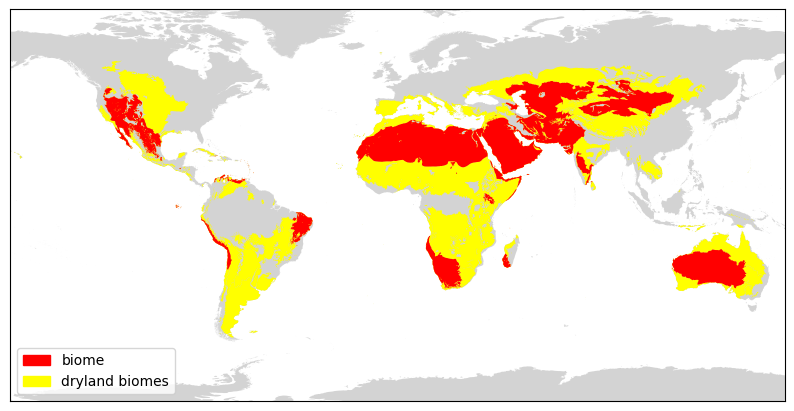

In [56]:
import matplotlib.patches as mpatches

# Plot the world map
fig, ax = plt.subplots(1, 1, figsize=(10, 8))
gdf_world_10m.plot(ax=ax, color='lightgrey', edgecolor='none')

# Set the title and remove axis
#ax.set_title('Dryland Biomes', fontsize=10)
ax.set_xlim([-160, 160])
ax.set_ylim([-80, 80])

ax.set_xticks([])
ax.set_yticks([])
ax.set_xticklabels([])
ax.set_yticklabels([])

gdf_biomeA_shp.plot(ax=ax, color='yellow', edgecolor='none')        # A - Tropical and Subtropical Dry Broadleaf Forests
gdf_biomeB_shp.plot(ax=ax, color='yellow', edgecolor='none')        # B - Tropical and Subtropical Grasslands, Savannas, and Shrublands
gdf_biomeC_shp.plot(ax=ax, color='yellow', edgecolor='none')        # C - Temparate Grasslands, Savannas, and Shrublands
gdf_biomeD_shp.plot(ax=ax, color='yellow', edgecolor='none')        # D - Montane Grasslands and Shrublands
gdf_biomeE_shp.plot(ax=ax, color='yellow', edgecolor='none')        # E - Mediterranean Forests, Woodlands, and Scrub
gdf_biomeF_shp.plot(ax=ax, color='yellow', edgecolor='none')        # F - Deserts and Xeric Shrublands 

gdf_current.plot(ax=ax, color='red', edgecolor='none') 
 
# Create custom legend handles
red_patch = mpatches.Patch(color="red", label="biome")
blue_patch = mpatches.Patch(color="yellow", label="dryland biomes")

ax.legend(handles=[red_patch, blue_patch], loc="lower left", fontsize=10)

plt.savefig("output_plot.jpg", dpi=300, bbox_inches="tight")
plt.show()

## Are GLANCE points inside Biome polygons ?

In [57]:
gdf_polygon = gdf_current.copy()          # biome polygon
gdf_points = gdf.copy()                   # all global GLanCE points

In [58]:
# Perform a spatial join
joined = gpd.sjoin(gdf_points, gdf_polygon, how='left', predicate='within')

# Create your boolean column based on whether a match was found
gdf_points['inside_any'] = joined.index_right.notna()

In [59]:
# Filter points that are inside any polygon
points_inside = gdf_points[gdf_points['inside_any']]

# Print the filtered points
len(points_inside)

26623

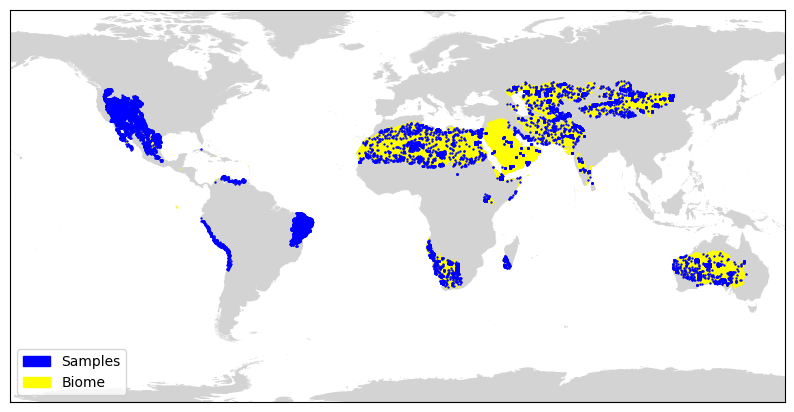

In [60]:
# Plot the world map
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
gdf_world_10m.plot(ax=ax, color='lightgrey', edgecolor='none')

# Set the title and remove axis
ax.set_xlim([-160, 160])
ax.set_ylim([-80, 80])

ax.set_xticks([])
ax.set_yticks([])
ax.set_xticklabels([])
ax.set_yticklabels([])

gdf_current.plot(ax=ax, color='yellow', edgecolor='none')
points_inside.plot(ax=ax, color='blue', markersize=0.5)

# Create custom legend handles
red_patch = mpatches.Patch(color="blue", label="Samples")
blue_patch = mpatches.Patch(color="yellow", label="Biome")

ax.legend(handles=[red_patch, blue_patch], loc="lower left", fontsize=10)

# Show the plot
plt.savefig("output_plot.jpg", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
points_inside.head()

In [61]:
len(points_inside)

26623

In [62]:
# How many samples per landcover class

sum=0
for i in range(0,7):
    y=np.sum((points_inside['level3'] == i))
    print(i, level3[i], '=', y)
    sum=sum+y
print('Total Samples =',sum,'\n')

0 Water(0) = 379
1 Developed(1) = 760
2 Barren(2) = 6881
3 Trees(3) = 1061
4 Shrub(4) = 6166
5 Grassland(5) = 8616
6 Agriculture(6) = 2760
Total Samples = 26623 



## Save geodataframe - each one contains only samples for that Biome

In [63]:
# save dataframe to parquet file for rereading into Notebook
gdf_save = points_inside.drop(columns="inside_any")
gdf_save.to_parquet('../GLANCE_data/gdf_biomeF_level3_samples.parquet')